# UK Boiler Upgrade Scheme
### The 2023 grant increase and differences in local uptake

**Did activity change after the grant uplift? Which councils have lower uptake than their housing characteristics suggest?**

We use six official datasets for an independent educational analysis covering England and Wales. Applications measure requests; paid redemptions follow completed installations but record payment timing. Neither is the wider installation market. Sources and detailed notes are in the [README](../README.md).

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display, Markdown
import statsmodels.api as sm
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance
from threadpoolctl import threadpool_limits
import openpyxl

ROOT = Path.cwd().resolve()
if not (ROOT / "data/raw").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/raw").is_dir(), "Run from the project root or notebooks folder"
RAW, PROCESSED, OUT = ROOT / "data/raw", ROOT / "data/processed", ROOT / "outputs"
PROCESSED.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 10)
pd.set_option("display.max_colwidth", None)

BLUE, TEAL, ORANGE, GREY = "#2463A0", "#168577", "#C58030", "#75818C"
plt.rcParams.update(
    {
        "figure.figsize": (11, 4.4),
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlepad": 12,
        "axes.labelcolor": "#354352",
        "text.color": "#223140",
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.alpha": 0.14,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=[BLUE, TEAL, ORANGE, GREY]),
    }
)

In [2]:
def save_plot(name):
    """Embed the current figure and keep an export for reuse."""
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


def date_axis(ax, ticks=6):
    locator = mdates.AutoDateLocator(minticks=3, maxticks=ticks)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def policy_dates(ax, labels=False):
    for date, text, colour, style in [
        ("2023-09-20", "20 Sep: announcement", ORANGE, ":"),
        ("2023-10-23", "23 Oct: grant uplift", GREY, "--"),
    ]:
        ax.axvline(
            pd.Timestamp(date), color=colour, ls=style, lw=1.4, label=text if labels else None
        )

In [3]:
def unique_file(pattern):
    matches = sorted(RAW.glob(pattern))
    assert len(matches) == 1, f"Ambiguous/missing source {pattern}: {matches}"
    return matches[0]


files = {
    "BUS": unique_file("Boiler*.xlsx"),
    "Deployment": unique_file("heat-pump*.xlsx"),
    "Gas": unique_file("Subnational*.xlsx"),
    **{key: unique_file(f"{key}*.csv") for key in ["TS044", "TS046", "TS054"]},
}


def raw_hashes():
    return {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in files.values()}


initial_hashes = raw_hashes()
manifest_path = OUT / "raw_sha256.json"
if manifest_path.exists():
    assert (
        json.loads(manifest_path.read_text()) == initial_hashes
    ), "Raw files changed since first run"
else:
    manifest_path.write_text(json.dumps(initial_hashes, indent=2))
versions = {
    name: metadata.version(name)
    for name in [
        "pandas",
        "numpy",
        "matplotlib",
        "scipy",
        "statsmodels",
        "scikit-learn",
        "openpyxl",
        "nbformat",
        "nbclient",
        "ipykernel",
        "threadpoolctl",
        "streamlit",
    ]
}
environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "seed": SEED,
    "numeric_threads": 1,
    "packages": versions,
}
(OUT / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
display(
    pd.DataFrame(
        {
            "Python": [platform.python_version()],
            "Sources": [len(files)],
            "Raw hashes": ["Verified against original manifest"],
            "Random seed": [SEED],
        }
    )
)

,Python,Sources,Raw hashes,Random seed
0,3.12.10,6,Verified against original manifest,42


## 1. What is in the files?

The Excel sheets contain titles, notes and hierarchy totals, so they need separate parsers. We keep a full sheet inventory and header audit on disk; only a small sample is shown here.

In [4]:
roles = {
    "BUS": (
        "DESNZ / Ofgem",
        "May 2022–September 2026",
        "29 October 2026 (cover)",
        "Policy outcomes; cumulative LA counts",
    ),
    "Deployment": (
        "DESNZ / MCS",
        "2018 Q1–2026 Q2",
        "10 September 2026",
        "Wider retrofit market context",
    ),
    "Gas": ("DESNZ", "2015–2024; use 2024", "18 December 2025 (cover)", "Off-gas property share"),
    "TS044": ("ONS", "Census 2021", "28 March 2023 (v4)", "Accommodation / household denominator"),
    "TS046": ("ONS", "Census 2021", "28 March 2023 (v4)", "Existing heating"),
    "TS054": ("ONS", "Census 2021", "28 March 2023 (v4)", "Tenure"),
}
inventory = pd.DataFrame(
    [
        {
            "source": k,
            "file": p.name,
            "publisher": roles[k][0],
            "reference": roles[k][1],
            "published": roles[k][2],
            "role": roles[k][3],
            "licence": "OGL v3 except third-party rights; see source notes",
        }
        for k, p in files.items()
    ]
)
inventory.to_csv(PROCESSED / "source_inventory.csv", index=False)
display(inventory[["source", "publisher", "reference", "role"]])

,source,publisher,reference,role
0,BUS,DESNZ / Ofgem,May 2022–September 2026,Policy outcomes; cumulative LA counts
1,Deployment,DESNZ / MCS,2018 Q1–2026 Q2,Wider retrofit market context
2,Gas,DESNZ,2015–2024; use 2024,Off-gas property share
3,TS044,ONS,Census 2021,Accommodation / household denominator
4,TS046,ONS,Census 2021,Existing heating
5,TS054,ONS,Census 2021,Tenure


In [5]:
sheet_rows, previews = ([], {})
for source in ["BUS", "Deployment", "Gas"]:
    book = openpyxl.load_workbook(files[source], read_only=False, data_only=True)
    for sheet in book:
        rows = list(
            sheet.iter_rows(
                min_row=1,
                max_row=min(sheet.max_row, 15),
                max_col=min(sheet.max_column, 10),
                values_only=True,
            )
        )
        sheet_rows.append(
            {
                "source": source,
                "sheet": sheet.title,
                "rows": sheet.max_row,
                "columns": sheet.max_column,
                "merged_ranges": str(list(sheet.merged_cells.ranges)[:10]),
            }
        )
        previews[f"{source}: {sheet.title}"] = [
            [str(x) if x is not None else None for x in r] for r in rows
        ]
    book.close()
sheet_inventory = pd.DataFrame(sheet_rows)
sheet_inventory.to_csv(PROCESSED / "worksheet_inventory.csv", index=False)
(OUT / "header_previews.json").write_text(json.dumps(previews, indent=2), encoding="utf-8")
useful_sheets = ["M1.1", "M1.2", "Q1.2", "A1.7", "Table 1.2", "2024"]
display(
    sheet_inventory.loc[
        sheet_inventory.sheet.isin(useful_sheets), ["source", "sheet", "rows", "columns"]
    ]
)
display(pd.DataFrame(previews["BUS: M1.1"][6:10]).iloc[:, :6])

,source,sheet,rows,columns
13,BUS,M1.1,34,56
14,BUS,M1.2,57,61
17,BUS,Q1.2,372,6
27,BUS,A1.7,371,8
35,Deployment,Table 1.2,44,17
47,Gas,2024,371,7


,0,1,2,3,4,5
0,Voucher status,Technology type,May\n2022,Jun\n2022,Jul\n2022,Aug\n2022
1,Voucher applications received,All technology types,1122,1577,1668,1390
2,Voucher applications received,Air-to-Water Heat Pumps,1088,1528,1598,1318
3,Voucher applications received,Air-to-Air Heat Pumps,0,0,0,0


In [6]:
census_raw = {key: pd.read_csv(files[key]) for key in ["TS044", "TS046", "TS054"]}
csv_checks = pd.DataFrame(
    [
        {
            "source": key,
            "rows": len(frame),
            "columns": len(frame.columns),
            "authorities": frame.iloc[:, 0].nunique(),
            "categories": frame.iloc[:, 3].nunique(),
            "duplicate_keys": int(frame.duplicated([frame.columns[0], frame.columns[2]]).sum()),
        }
        for key, frame in census_raw.items()
    ]
)
display(csv_checks)
display(census_raw["TS044"].head(3))

,source,rows,columns,authorities,categories,duplicate_keys
0,TS044,2648,5,331,8,0
1,TS046,4303,5,331,13,0
2,TS054,2979,5,331,9,0


,Lower tier local authorities Code,Lower tier local authorities,Accommodation type (8 categories) Code,Accommodation type (8 categories),Observation
0,E06000001,Hartlepool,1,Detached,8086
1,E06000001,Hartlepool,2,Semi-detached,14537
2,E06000001,Hartlepool,3,Terraced,13469


## 2. Clean the monthly series

Missing and suppressed values stay missing; unexpected numeric strings raise an error. We check duplicate keys, consecutive months, technology totals and published row totals before using hydronic heat pump counts. Biomass and air-to-air systems are excluded to keep the technology definition consistent.

In [7]:
missing_markers = {"", "[c1]", "[c2]", "[c3]", "[x]", "[z]", "..", "-", "–", "—", "n/a", "na"}


def numeric(series):
    text = series.astype("string").str.strip().str.replace(",", "", regex=False)
    missing = text.str.lower().isin(missing_markers) | series.isna()
    result = pd.to_numeric(text.mask(missing), errors="coerce")
    unexpected = result.isna() & ~missing
    assert not unexpected.any(), f"Unexpected numeric strings: {text[unexpected].unique()}"
    return result.astype(float)


def find_header(path, sheet, first_label):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    hits = raw.index[raw.iloc[:, 0].eq(first_label)]
    assert len(hits) == 1, (sheet, first_label, hits)
    table = raw.iloc[hits[0] + 1 :].copy()
    table.columns = raw.iloc[hits[0]].tolist()
    unnamed = table.columns.isna()
    if unnamed.any():
        blank = (
            table.loc[:, unnamed].astype("string").apply(lambda s: s.str.strip()).replace("", pd.NA)
        )
        assert blank.isna().all().all(), f"Unlabelled nonempty data in {sheet}"
        table = table.loc[:, ~unnamed]
    assert not table.columns.duplicated().any(), f"Duplicate headings in {sheet}"
    return table.dropna(how="all").reset_index(drop=True)

In [8]:
monthly_wide = find_header(files["BUS"], "M1.1", "Voucher status")
monthly_columns = [c for c in monthly_wide if re.fullmatch("[A-Za-z]{3}\\s+20\\d{2}", str(c))]
assert monthly_columns
monthly_long = monthly_wide.melt(
    id_vars=["Voucher status", "Technology type"],
    value_vars=monthly_columns,
    var_name="month",
    value_name="value",
)
monthly_long["month"] = pd.to_datetime(
    monthly_long["month"].str.replace("\\s+", " ", regex=True), format="%b %Y"
)
monthly_long["value"] = numeric(monthly_long["value"])
assert not monthly_long.duplicated(["Voucher status", "Technology type", "month"]).any()
assert monthly_long["value"].notna().all()
assert monthly_long["value"].ge(0).all(), "Investigate negative flow counts before fitting"

In [9]:
components = (
    monthly_long[monthly_long["Technology type"].ne("All technology types")]
    .groupby(["Voucher status", "month"])["value"]
    .sum()
)
totals = monthly_long[monthly_long["Technology type"].eq("All technology types")].set_index(
    ["Voucher status", "month"]
)["value"]
pd.testing.assert_series_equal(components.sort_index(), totals.sort_index(), check_names=False)
hydronic = [
    "Air-to-Water Heat Pumps",
    "Ground Source Heat Pumps",
    "Shared Ground Loop Ground Source Heat Pumps",
]
assert set(hydronic).issubset(monthly_long["Technology type"].unique())
national = (
    monthly_long[monthly_long["Technology type"].isin(hydronic)]
    .groupby(["month", "Voucher status"])["value"]
    .sum()
    .unstack()
)
national = national.rename(
    columns={
        "Voucher applications received": "applications",
        "Vouchers issued": "issued",
        "Redemption applications received": "redemption_applications",
        "Redemptions paid": "paid",
    }
)
national.index.name = "month"
assert national.index.equals(
    pd.date_range(national.index.min(), national.index.max(), freq="MS", name="month")
)
for _, row in monthly_wide.iterrows():
    assert np.isclose(numeric(row[monthly_columns]).sum(), float(row["Total"]))
national.to_csv(PROCESSED / "national_monthly_hydronic.csv")
monthly_long.to_csv(PROCESSED / "national_monthly_all_technologies_long.csv", index=False)
display(national[["applications", "issued", "paid"]].iloc[[0, 1, -2, -1]])
display(
    Markdown(
        f"**{len(national)} consecutive months**, with {national.paid.sum():,.0f} cumulative paid redemptions. All technology components and published row totals reconcile."
    )
)

Voucher status,applications,issued,paid
month,,,
2022-05-01,1110.0,17.0,7.0
2022-06-01,1558.0,827.0,144.0
2026-08-01,7445.0,5895.0,3258.0
2026-09-01,9721.0,6294.0,3327.0


**53 consecutive months**, with 96,185 cumulative paid redemptions. All technology components and published row totals reconcile.

In [10]:
regions_wide = find_header(files["BUS"], "M1.2", "Status")
region_months = [c for c in regions_wide if re.fullmatch("[A-Za-z]{3}\\s+20\\d{2}", str(c))]
regional_long = regions_wide.melt(
    id_vars=["Status", "Area Codes", "Country or Region"],
    value_vars=region_months,
    var_name="month",
    value_name="value",
)
regional_long["month"] = pd.to_datetime(
    regional_long["month"].str.replace("\\s+", " ", regex=True), format="%b %Y"
)
regional_long["value"] = numeric(regional_long["value"])
regional_long.to_csv(PROCESSED / "regional_monthly.csv", index=False)
region_codes = [f"E1200000{i}" for i in range(1, 10)] + ["W92000004"]

## 3. How has activity changed?

The full series gives context; the close-up shows the announcement and implementation separately. A gap between applications and payments compares different cohorts, so it is neither a conversion rate nor a measured backlog. The shaded 2026 period contains further scheme changes.

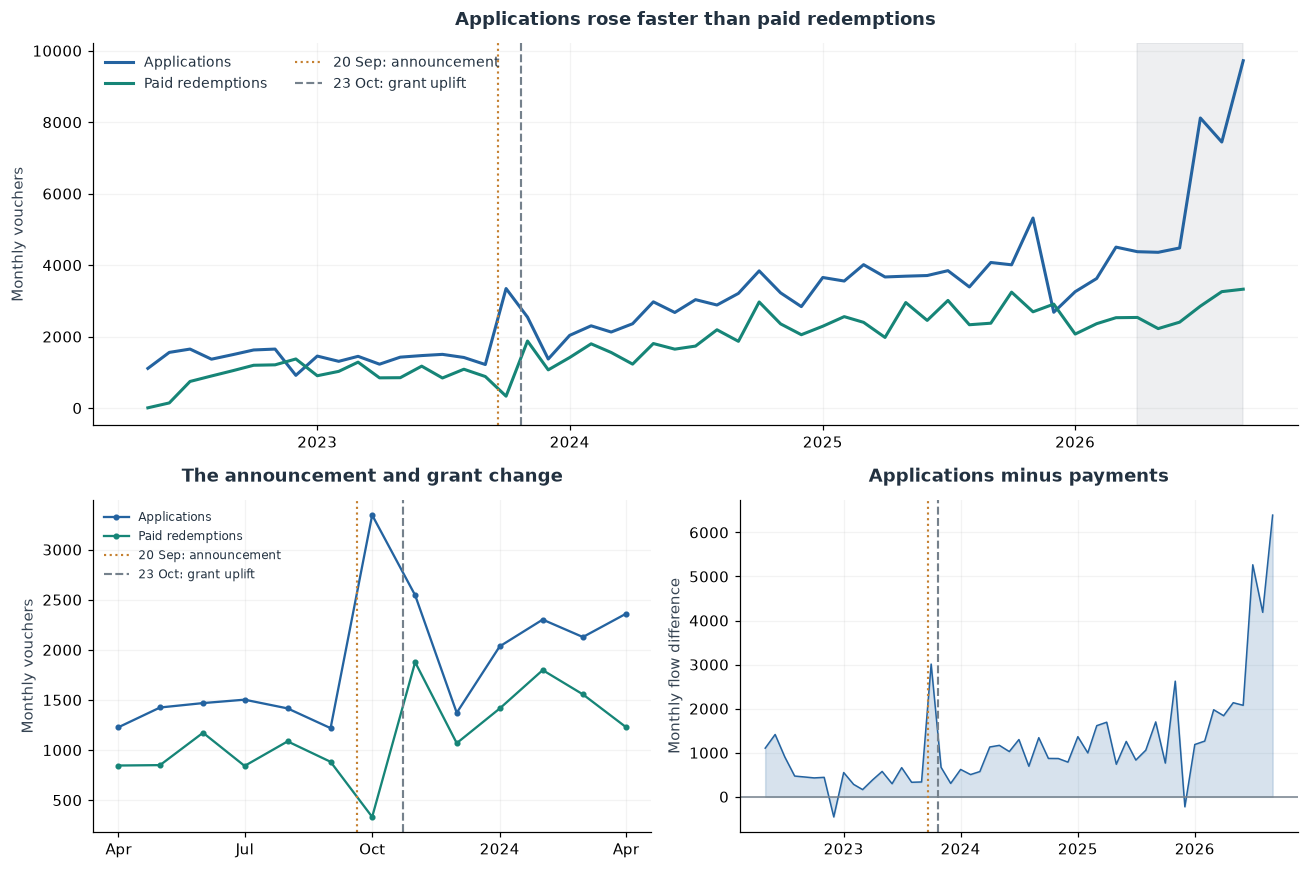

Applications reached 9,721 in September 2026. The October 2023 spike and payment dip show why monthly timing needs care.

In [11]:
fig = plt.figure(figsize=(12, 8))
grid = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
overview = fig.add_subplot(grid[0, :])
zoom = fig.add_subplot(grid[1, 0])
gap_ax = fig.add_subplot(grid[1, 1])
for column, label, colour in [
    ("applications", "Applications", BLUE),
    ("paid", "Paid redemptions", TEAL),
]:
    overview.plot(national.index, national[column], color=colour, label=label, lw=2)
    window = national.loc["2023-04":"2024-04"]
    zoom.plot(window.index, window[column], color=colour, marker="o", ms=3, label=label)
overview.axvspan(pd.Timestamp("2026-04-01"), national.index.max(), color=GREY, alpha=0.12)
overview.set(title="Applications rose faster than paid redemptions", ylabel="Monthly vouchers")
policy_dates(overview, labels=True)
overview.legend(loc="upper left", ncol=2, frameon=False, fontsize=9)
zoom.set(title="The announcement and grant change", ylabel="Monthly vouchers")
policy_dates(zoom, labels=True)
zoom.legend(fontsize=8, frameon=False, loc="upper left")
difference = national.applications - national.paid
gap_ax.fill_between(national.index, difference, 0, color=BLUE, alpha=0.18)
gap_ax.plot(national.index, difference, color=BLUE, lw=1)
gap_ax.axhline(0, color=GREY, lw=1)
gap_ax.set(title="Applications minus payments", ylabel="Monthly flow difference")
policy_dates(gap_ax)
for ax in [overview, zoom, gap_ax]:
    date_axis(ax, 6)
save_plot("national_activity")
display(
    Markdown(
        f"Applications reached {national.applications.max():,.0f} in {national.applications.idxmax():%B %Y}. The October 2023 spike and payment dip show why monthly timing needs care."
    )
)

### Are there seasonal patterns?

Each row below is a different year. This avoids hiding policy growth inside an average calendar month, although seasonality and policy changes still overlap. Blank squares are unavailable months, not zero activity.

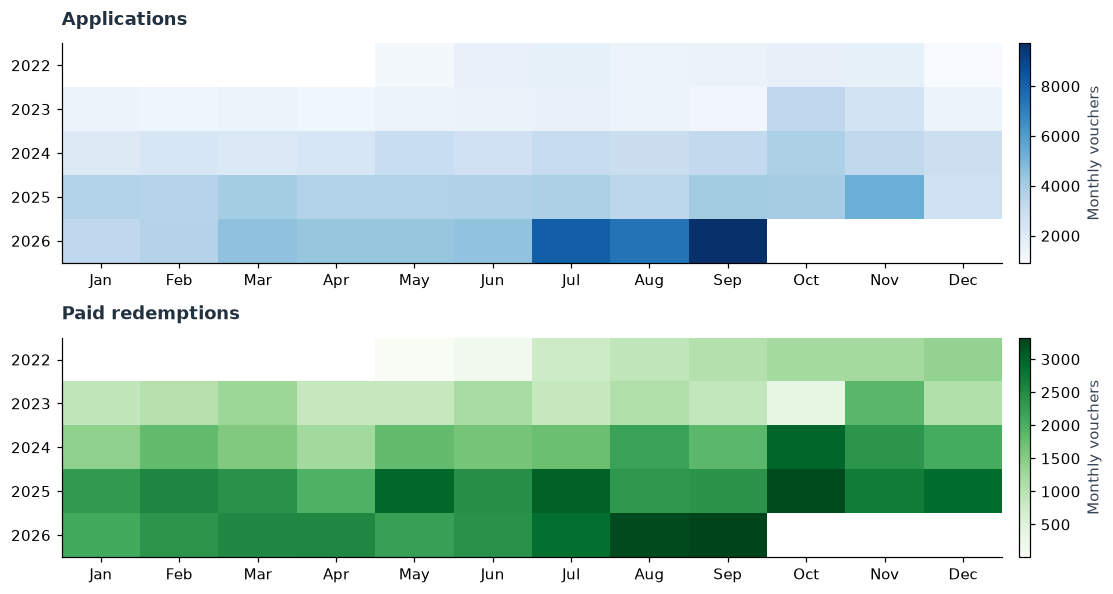

,mean,median,var,std,min,max
Voucher status,,,,,,
applications,3020.8,2884.0,3.114e+06,1764.8,916.0,9721.0
paid,1814.8,1868.0,7.182e+05,847.5,7.0,3327.0


December is often quieter, but the scale changes strongly between years. These patterns support a modest seasonal adjustment rather than treating months as independent observations.

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))
for ax, column, title, cmap in zip(
    axes, ["applications", "paid"], ["Applications", "Paid redemptions"], ["Blues", "Greens"]
):
    calendar = national.assign(year=national.index.year, month_number=national.index.month)
    calendar = calendar.pivot(index="year", columns="month_number", values=column).reindex(
        columns=range(1, 13)
    )
    image = ax.imshow(np.ma.masked_invalid(calendar.to_numpy()), aspect="auto", cmap=cmap)
    ax.set_xticks(
        range(12),
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    )
    ax.set_yticks(range(len(calendar)), calendar.index)
    ax.set_title(title, loc="left")
    ax.grid(False)
    fig.colorbar(image, ax=ax, pad=0.015, label="Monthly vouchers")
save_plot("seasonal_activity")
descriptive = (
    national[["applications", "paid"]].agg(["mean", "median", "var", "std", "min", "max"]).T
)
display(descriptive.round(1))
display(
    Markdown(
        "December is often quieter, but the scale changes strongly between years. These patterns support a modest seasonal adjustment rather than treating months as independent observations."
    )
)

In [13]:
pre_learning = national.loc["2022-06":"2023-08", "applications"]
mean_fit = sm.OLS(pre_learning.to_numpy(), np.ones((len(pre_learning), 1))).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3, "use_correction": True}, use_t=True
)
mean_ci = np.asarray(mean_fit.conf_int())[0]
display(
    pd.DataFrame(
        {
            "Pre-announcement applications": {
                "Months": len(pre_learning),
                "Mean": pre_learning.mean(),
                "Median": pre_learning.median(),
                "Standard deviation": pre_learning.std(),
                "HAC mean interval, lower": mean_ci[0],
                "HAC mean interval, upper": mean_ci[1],
                "Lag-one correlation": pre_learning.autocorr(1),
            }
        }
    ).round(2)
)

,Pre-announcement applications
Months,15.00
Mean,1434.53
Median,1455.00
Standard deviation,186.75
"HAC mean interval, lower",1345.51
"HAC mean interval, upper",1523.56
Lag-one correlation,-0.14


## 4. Before and after the grant uplift

The £7,500 grant started on 23 October 2023, following the 20 September announcement. We compare full pre-announcement months with November–April afterwards, excluding launch and transition months. This comparison describes change; it does not isolate the grant's contribution.

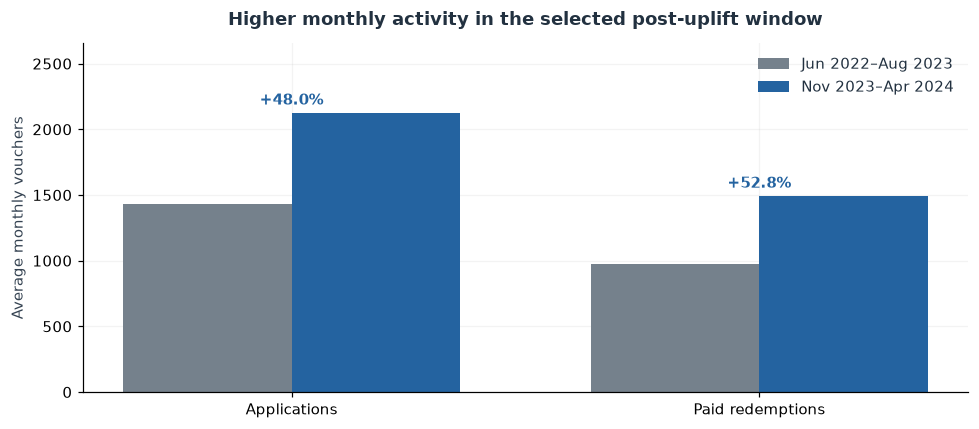

,Nov 2022–Apr 2023,Nov 2023–Apr 2024,change_pct
Voucher status,,,
applications,1334.3,2123.7,59.2
paid,1107.8,1490.8,34.6


Applications rose 48.0% in the main comparison, or 59.2% using matching calendar months. Market growth and administrative timing remain possible explanations.

In [14]:
before = national.loc["2022-06":"2023-08", ["applications", "paid"]].mean()
after = national.loc["2023-11":"2024-04", ["applications", "paid"]].mean()
before_after = pd.DataFrame(
    {"pre_mean": before, "post_mean": after, "change_pct": 100 * (after / before - 1)}
)
matched_seasons = pd.DataFrame(
    {
        "Nov22_Apr23": national.loc["2022-11":"2023-04", ["applications", "paid"]].mean(),
        "Nov23_Apr24": after,
    }
)
matched_seasons["change_pct"] = 100 * (matched_seasons.iloc[:, 1] / matched_seasons.iloc[:, 0] - 1)
before_after.to_csv(OUT / "before_after.csv")
fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(2)
ax.bar(positions - 0.18, before, width=0.36, color=GREY, label="Jun 2022–Aug 2023")
ax.bar(positions + 0.18, after, width=0.36, color=BLUE, label="Nov 2023–Apr 2024")
for i, outcome in enumerate(["applications", "paid"]):
    change = before_after.loc[outcome, "change_pct"]
    ax.text(i, after[outcome] + 65, f"+{change:.1f}%", ha="center", fontweight="bold", color=BLUE)
ax.set_xticks(positions, ["Applications", "Paid redemptions"])
ax.set(
    ylabel="Average monthly vouchers",
    title="Higher monthly activity in the selected post-uplift window",
)
ax.set_ylim(0, after.max() * 1.25)
ax.legend(frameon=False)
save_plot("before_after_activity")
display(
    matched_seasons.rename(
        columns={"Nov22_Apr23": "Nov 2022–Apr 2023", "Nov23_Apr24": "Nov 2023–Apr 2024"}
    ).round(1)
)
display(
    Markdown(
        f"Applications rose {before_after.loc['applications','change_pct']:.1f}% in the main comparison, or {matched_seasons.loc['applications','change_pct']:.1f}% using matching calendar months. Market growth and administrative timing remain possible explanations."
    )
)

## 5. Does the change exceed the fitted trend?

Segmented regression estimates a pre-trend, a November level change and a slope change, with one annual sine/cosine pair. The model ends April 2024, before insulation rules changed. Only 15 pre and six fully post months remain; the no-break projection is conditional, not an identified causal counterfactual.

In [15]:
def its_design(index, intervention="2023-11-01", seasonal=True):
    t = np.asarray((index.year - 2022) * 12 + index.month - 6, dtype=float)
    cut = pd.Timestamp(intervention)
    t0 = (cut.year - 2022) * 12 + cut.month - 6
    post = np.asarray(index >= cut, dtype=float)
    x = pd.DataFrame(
        {"const": 1.0, "time": t, "post": post, "post_time": post * (t - t0)}, index=index
    )
    if seasonal:
        x["sin12"] = np.sin(2 * np.pi * t / 12)
        x["cos12"] = np.cos(2 * np.pi * t / 12)
    return x


def fit_its(
    outcome, end="2024-04-01", intervention="2023-11-01", drop_transition=True, seasonal=True, lag=3
):
    y = national.loc["2022-06-01":end, outcome].copy()
    if drop_transition:
        y = y[~y.index.isin(pd.to_datetime(["2023-09-01", "2023-10-01"]))]
    x = its_design(y.index, intervention, seasonal)
    fit = sm.OLS(y, x).fit(
        cov_type="HAC", cov_kwds={"maxlags": lag, "use_correction": True}, use_t=True
    )
    if drop_transition:
        # Preserve calendar lags across the two omitted months; these are scores, not imputed outcomes.
        scores = (
            x.mul(fit.resid, axis=0)
            .reindex(pd.date_range(y.index.min(), y.index.max(), freq="MS"), fill_value=0)
            .to_numpy()
        )
        meat = scores.T @ scores
        for distance in range(1, lag + 1):
            cross = scores[distance:].T @ scores[:-distance]
            meat += (1 - distance / (lag + 1)) * (cross + cross.T)
        bread = np.asarray(fit.normalized_cov_params)
        calendar_covariance = len(y) / fit.df_resid * bread @ meat @ bread
        fit.cov_params_default[:] = calendar_covariance
        np.testing.assert_allclose(fit.cov_params(), calendar_covariance)
    return (y, x, fit)

In [16]:
its_models, its_rows = ({}, [])
for outcome in ["applications", "paid"]:
    y, x, fit = fit_its(outcome)
    its_models[outcome] = (y, x, fit)
    for term in ["time", "post", "post_time"]:
        low, high = fit.conf_int().loc[term]
        its_rows.append(
            {
                "outcome": outcome,
                "term": term,
                "estimate": fit.params[term],
                "CI_low": low,
                "CI_high": high,
                "p_value": fit.pvalues[term],
            }
        )
its_results = pd.DataFrame(its_rows)
its_results.to_csv(OUT / "its_coefficients.csv", index=False)
display(its_results[["outcome", "term", "estimate", "CI_low", "CI_high"]].round(1))

,outcome,term,estimate,CI_low,CI_high
0,applications,time,-9.0,-16.7,-1.4
1,applications,post,783.0,259.2,1306.7
2,applications,post_time,50.1,-79.1,179.4
3,paid,time,35.2,6.5,63.9
4,paid,post,-107.3,-687.4,472.7
5,paid,post_time,30.4,-94.2,155.1


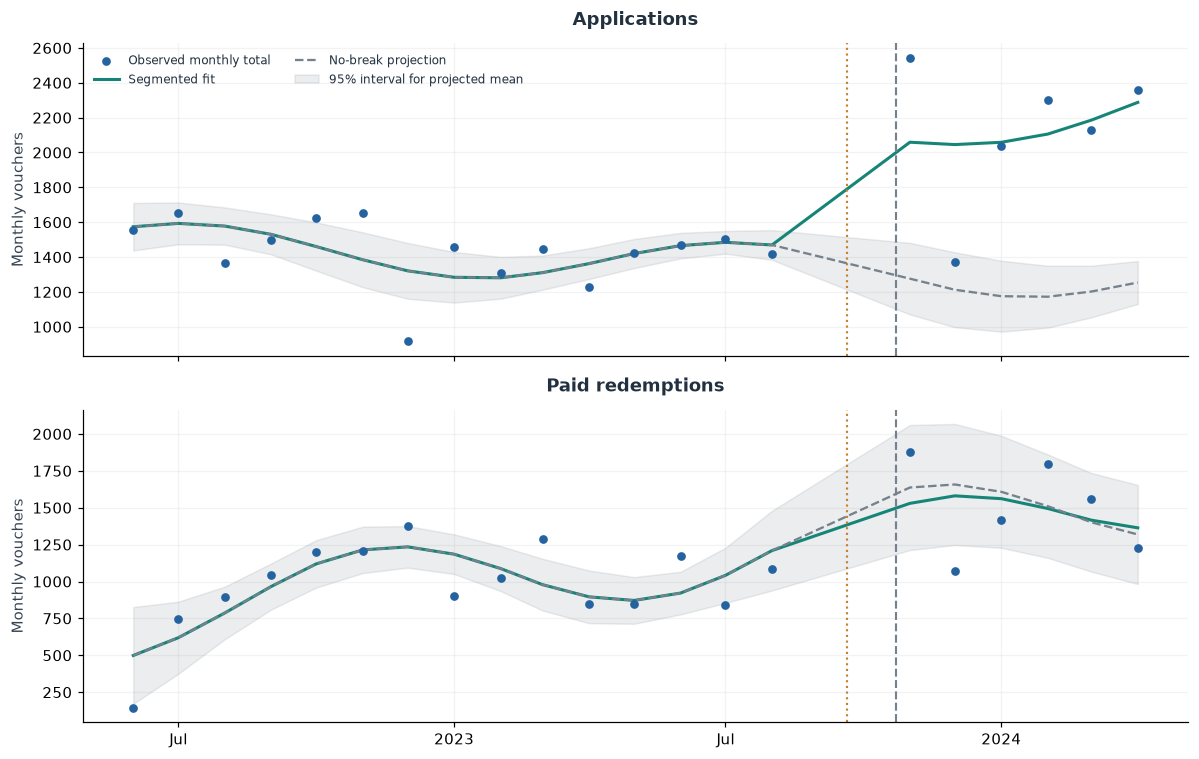

,outcome,average_post_contrast,CI_low,CI_high
0,applications,908.3,665.7,1151.0
1,paid,-31.2,-418.3,355.8


The fitted application contrast averages **908/month** (95% HAC interval 666–1,151). The payment interval includes zero; neither contrast establishes causation.

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
contrasts, fitted_rows = [], []
for ax, (outcome, (observed, design, model)) in zip(axes, its_models.items()):
    counterfactual = design.copy()
    counterfactual[["post", "post_time"]] = 0.0
    projection = model.get_prediction(counterfactual).summary_frame(alpha=0.05)
    fitted = model.predict(design)
    ax.scatter(observed.index, observed, color=BLUE, s=22, label="Observed monthly total", zorder=3)
    ax.plot(observed.index, fitted, color=TEAL, lw=2, label="Segmented fit")
    ax.plot(observed.index, projection["mean"], color=GREY, ls="--", label="No-break projection")
    ax.fill_between(
        observed.index,
        projection.mean_ci_lower.to_numpy(),
        projection.mean_ci_upper.to_numpy(),
        color=GREY,
        alpha=0.14,
        label="95% interval for projected mean",
    )
    policy_dates(ax)
    ax.set(
        title="Applications" if outcome == "applications" else "Paid redemptions",
        ylabel="Monthly vouchers",
    )
    contrast_vector = (design.loc["2023-11":] - counterfactual.loc["2023-11":]).mean().to_numpy()
    test = model.t_test(contrast_vector)
    low, high = np.asarray(test.conf_int())[0]
    contrasts.append(
        {
            "outcome": outcome,
            "average_post_contrast": float(np.asarray(test.effect).item()),
            "CI_low": float(low),
            "CI_high": float(high),
            "negative_counterfactual_months": int((projection["mean"] < 0).sum()),
        }
    )
    fitted_rows.append(
        pd.DataFrame(
            {
                "month": observed.index,
                "outcome": outcome,
                "observed": observed.to_numpy(),
                "fitted": fitted.to_numpy(),
                "counterfactual": projection["mean"].to_numpy(),
                "CI_low": projection.mean_ci_lower.to_numpy(),
                "CI_high": projection.mean_ci_upper.to_numpy(),
            }
        )
    )
axes[0].legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
date_axis(axes[-1])
save_plot("its_counterfactual")
contrasts = pd.DataFrame(contrasts)
contrasts.to_csv(OUT / "its_post_contrasts.csv", index=False)
pd.concat(fitted_rows, ignore_index=True).to_csv(OUT / "its_fitted_monthly.csv", index=False)
display(contrasts.drop(columns="negative_counterfactual_months").round(1))
app_contrast = contrasts.set_index("outcome").loc["applications"]
display(
    Markdown(
        f"The fitted application contrast averages **{app_contrast.average_post_contrast:,.0f}/month** (95% HAC interval {app_contrast.CI_low:,.0f}–{app_contrast.CI_high:,.0f}). The payment interval includes zero; neither contrast establishes causation."
    )
)

### How sensitive is the result?

We vary timing, transition handling, seasonality, HAC lags and the end date. Longer windows include later policies; different break dates estimate different contrasts. The intervals below describe model uncertainty, not uncertainty about confounding.

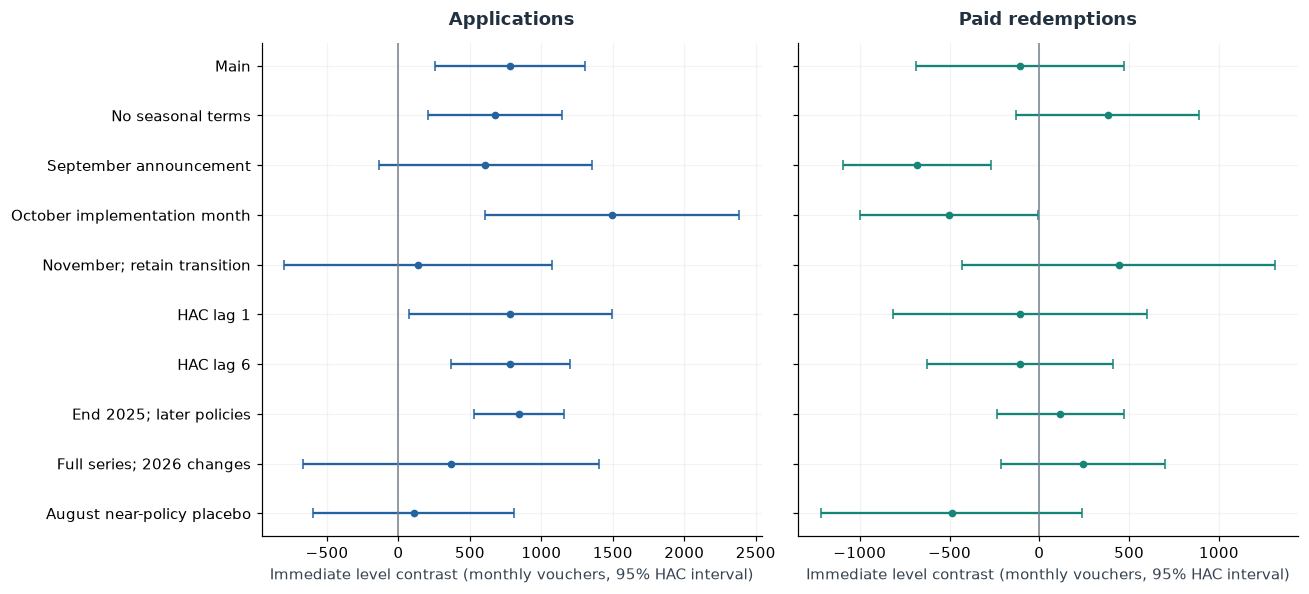

Retaining transition months with a November break weakens the application level signal. Payment estimates are especially sensitive to timing and seasonality, so the uplift cannot explain the whole later trajectory.

In [18]:
specs = [
    ("Main", "2024-04-01", "2023-11-01", True, True, 3),
    ("No seasonal terms", "2024-04-01", "2023-11-01", True, False, 3),
    ("September announcement", "2024-04-01", "2023-09-01", False, True, 3),
    ("October implementation month", "2024-04-01", "2023-10-01", False, True, 3),
    ("November; retain transition", "2024-04-01", "2023-11-01", False, True, 3),
    ("HAC lag 1", "2024-04-01", "2023-11-01", True, True, 1),
    ("HAC lag 6", "2024-04-01", "2023-11-01", True, True, 6),
    ("End 2025; later policies", "2025-12-01", "2023-11-01", True, True, 3),
    ("Full series; 2026 changes", "2026-09-01", "2023-11-01", True, True, 3),
    ("August near-policy placebo", "2024-04-01", "2023-08-01", False, True, 3),
]
sensitivity_rows = []
for outcome in ["applications", "paid"]:
    for label, end, cut, drop, season, lag in specs:
        y, x, f = fit_its(outcome, end, cut, drop, season, lag)
        low, high = f.conf_int().loc["post"]
        sensitivity_rows.append(
            {
                "outcome": outcome,
                "specification": label,
                "n": len(y),
                "level": f.params["post"],
                "level_low": low,
                "level_high": high,
                "slope_change": f.params["post_time"],
                "AIC_within_same_sample_only": f.aic,
            }
        )
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT / "its_sensitivity.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
labels = [s[0] for s in specs]
for ax, outcome in zip(axes, ["applications", "paid"]):
    results = sensitivity.loc[sensitivity.outcome.eq(outcome)]
    positions = np.arange(len(results))
    ax.errorbar(
        results.level,
        positions,
        xerr=np.vstack([results.level - results.level_low, results.level_high - results.level]),
        fmt="o",
        color=BLUE if outcome == "applications" else TEAL,
        capsize=3,
        ms=4,
    )
    ax.axvline(0, color=GREY, lw=1)
    ax.set_title("Applications" if outcome == "applications" else "Paid redemptions")
    ax.set_xlabel("Immediate level contrast (monthly vouchers, 95% HAC interval)")
axes[0].set_yticks(np.arange(len(labels)), labels)
axes[0].invert_yaxis()
save_plot("its_sensitivity")
display(
    Markdown(
        "Retaining transition months with a November break weakens the application level signal. Payment estimates are especially sensitive to timing and seasonality, so the uplift cannot explain the whole later trajectory."
    )
)

### Check residuals and a simple forecast baseline

HAC errors allow short-range time dependence but cannot repair a misspecified trend. Residual correlations below use calendar lags, preserving the omitted months. March–April 2024 is a two-month forecast holdout: useful as a check, too short for reliable model selection.

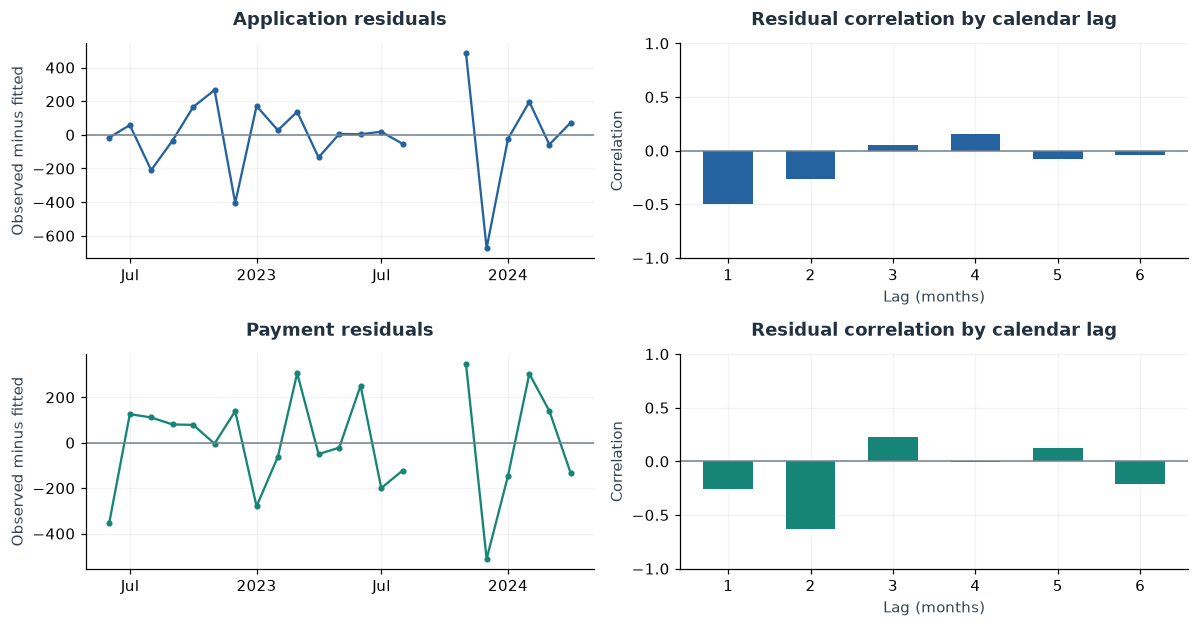

The large November–December residual swings warn against a smooth-response interpretation. The lag plot is descriptive; no significance bands or gap-compressed Ljung–Box test are used.

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.8))
for row, (outcome, (observed, design, model)) in enumerate(its_models.items()):
    residuals = model.resid.reindex(
        pd.date_range(observed.index.min(), observed.index.max(), freq="MS")
    )
    axes[row, 0].plot(
        residuals.index, residuals, color=BLUE if row == 0 else TEAL, marker="o", ms=3
    )
    axes[row, 0].axhline(0, color=GREY, lw=1)
    axes[row, 0].set(
        title=("Application" if row == 0 else "Payment") + " residuals",
        ylabel="Observed minus fitted",
    )
    date_axis(axes[row, 0], 5)
    lags = np.arange(1, 7)
    axes[row, 1].bar(
        lags,
        [residuals.autocorr(int(lag)) for lag in lags],
        color=BLUE if row == 0 else TEAL,
        width=0.6,
    )
    axes[row, 1].axhline(0, color=GREY, lw=1)
    axes[row, 1].set(
        title="Residual correlation by calendar lag",
        xlabel="Lag (months)",
        ylabel="Correlation",
        ylim=(-1, 1),
    )
save_plot("its_residuals")
display(
    Markdown(
        "The large November–December residual swings warn against a smooth-response interpretation. The lag plot is descriptive; no significance bands or gap-compressed Ljung–Box test are used."
    )
)

In [20]:
baseline_rows = []
for outcome in ["applications", "paid"]:
    y, x, f = fit_its(outcome, end="2024-02-01")
    test = national.loc["2024-03":"2024-04", outcome]
    xt = its_design(test.index)
    no_break = sm.OLS(y, x.drop(columns=["post", "post_time"])).fit()
    predictions = {
        "Segmented": f.predict(xt),
        "Trend + season": no_break.predict(xt.drop(columns=["post", "post_time"])),
        "Same month last year": national.loc[
            test.index - pd.DateOffset(years=1), outcome
        ].to_numpy(),
    }
    for label, pred in predictions.items():
        baseline_rows.append(
            {
                "outcome": outcome,
                "model": label,
                "holdout_months": len(test),
                "MAE_vouchers": mean_absolute_error(test, pred),
            }
        )
time_baselines = pd.DataFrame(baseline_rows)
time_baselines.to_csv(OUT / "time_holdout_metrics.csv", index=False)
display(time_baselines.round(1))
display(
    Markdown(
        "The segmented model forecasts applications better on this holdout; the trend/season baseline forecasts payments better. Prediction accuracy does not validate the causal assumptions."
    )
)

,outcome,model,holdout_months,MAE_vouchers
0,applications,Segmented,2,84.3
1,applications,Trend + season,2,433.3
2,applications,Same month last year,2,906.0
3,paid,Segmented,2,152.9
4,paid,Trend + season,2,125.0
5,paid,Same month last year,2,327.5


The segmented model forecasts applications better on this holdout; the trend/season baseline forecasts payments better. Prediction accuracy does not validate the causal assumptions.

### What happened in the wider market?

We align deployment to England and Wales and use complete BUS quarters. MCS deployment records commissioning, while BUS records payments and has different eligibility. Subtracting these lines would not measure installations outside BUS, and the wider series is not an untreated control.

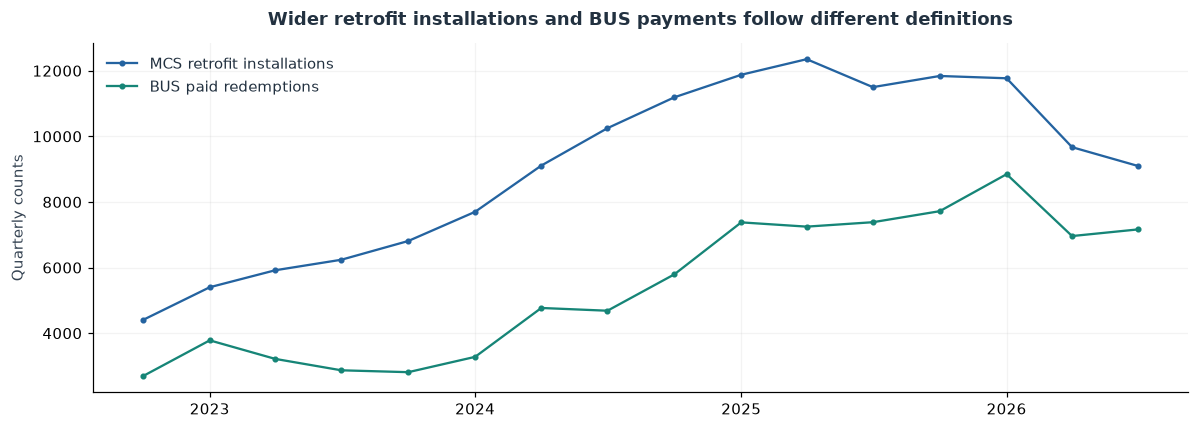

MCS retrofit installations reached 9,095 in 2026Q2, compared with 11,500 a year earlier. These figures provide market context rather than a causal comparison.

In [21]:
dep_raw = pd.read_excel(files["Deployment"], sheet_name="Table 1.2", header=None)
code_row = dep_raw.index[dep_raw.iloc[:, 0].eq("Area Codes and Country or Region")][0]
ew_col = dep_raw.columns[dep_raw.loc[code_row].eq("K04000001")][0]
dep = dep_raw.iloc[code_row + 2 :, [0, ew_col]].dropna(how="all").copy()
dep.columns = ["quarter_label", "retrofit_EW"]
parts = dep.quarter_label.str.extract("^(\\d{4}) Q([1-4]):")
assert parts.notna().all().all()
dep["quarter"] = pd.PeriodIndex(parts[0] + "Q" + parts[1], freq="Q")
dep["retrofit_EW"] = numeric(dep.retrofit_EW)
deployment = dep.set_index("quarter")[["retrofit_EW"]]
assert not deployment.index.duplicated().any()
bus_quarters = national.paid.groupby(national.index.to_period("Q")).sum().rename("BUS_paid")
comparison = deployment.join(bus_quarters)
comparison = comparison.loc["2022Q3":"2026Q2"]
fig, ax = plt.subplots(figsize=(11, 4))
dates = comparison.index.to_timestamp(how="end")
ax.plot(
    dates, comparison.retrofit_EW, color=BLUE, marker="o", ms=3, label="MCS retrofit installations"
)
ax.plot(dates, comparison.BUS_paid, color=TEAL, marker="o", ms=3, label="BUS paid redemptions")
ax.set(
    title="Wider retrofit installations and BUS payments follow different definitions",
    ylabel="Quarterly counts",
)
ax.legend(frameon=False)
date_axis(ax)
save_plot("wider_deployment")
deployment.to_csv(PROCESSED / "deployment_EW_quarterly.csv")
display(
    Markdown(
        f"MCS retrofit installations reached {deployment.iloc[-1,0]:,.0f} in {deployment.index[-1]}, compared with {deployment.iloc[-5,0]:,.0f} a year earlier. These figures provide market context rather than a causal comparison."
    )
)

## 6. Which councils can we compare?

BUS contains 318 current districts. We aggregate whole predecessor districts for four unitary reorganisations, then join by code. Barnsley and Sheffield have changed boundaries, not just names; without reallocation weights, both remain in the exclusion audit rather than receiving unsafe matches.

In [22]:
la_raw = find_header(files["BUS"], "Q1.2", "Area Codes")
region = None
region_for_row = []
for _, r in la_raw.iterrows():
    if str(r["Area Codes"]) in region_codes:
        region = r["Country or Region"]
    region_for_row.append(region)
la_raw["region"] = region_for_row
is_la = la_raw["Area Codes"].astype(str).str.match("^(E0[6-9]|W06)\\d{6}$")
la = la_raw.loc[
    is_la,
    [
        "Area Codes",
        "County or Unitary Authority",
        "Local Authority Districts",
        "Heat pump technologies [note 24]",
        "region",
    ],
].copy()
la["name"] = (
    la["Local Authority Districts"]
    .fillna(la["County or Unitary Authority"])
    .str.replace("\\s*\\[note \\d+\\]", "", regex=True)
    .str.strip()
)
la = la.rename(columns={"Area Codes": "code", "Heat pump technologies [note 24]": "paid"})[
    ["code", "name", "region", "paid"]
]
la["paid_raw"] = la.paid.astype(str)
la["paid"] = numeric(la.paid)
assert la.code.is_unique and la.region.notna().all()
assert (la.paid.dropna() >= 0).all()
national_q = numeric(
    la_raw.loc[la_raw["Area Codes"].eq("K04000001"), "Heat pump technologies [note 24]"]
).iloc[0]
assert la.paid.notna().all() and np.isclose(la.paid.sum(), national_q)
assert np.isclose(national_q, national.paid.sum())

In [23]:
successors = {
    "E06000063": ["E07000026", "E07000028", "E07000029"],
    "E06000064": ["E07000027", "E07000030", "E07000031"],
    "E06000065": [
        "E07000163",
        "E07000164",
        "E07000165",
        "E07000166",
        "E07000167",
        "E07000168",
        "E07000169",
    ],
    "E06000066": ["E07000187", "E07000188", "E07000189", "E07000246"],
}
crosswalk = {old: new for new, old_codes in successors.items() for old in old_codes}
crosswalk_table = pd.DataFrame(crosswalk.items(), columns=["census_code", "BUS_code"])
names2021 = census_raw["TS044"].iloc[:, :2].drop_duplicates()
names2021.columns = ["census_code", "census_name"]
crosswalk_table = crosswalk_table.merge(names2021, on="census_code", validate="one_to_one")
crosswalk_table.to_csv(PROCESSED / "geography_crosswalk.csv", index=False)
display(
    crosswalk_table.groupby("BUS_code").agg(
        predecessor_districts=("census_code", "size"),
        census_areas=("census_name", lambda names: ", ".join(names)),
    )
)

,predecessor_districts,census_areas
BUS_code,,
E06000063,3,"Allerdale, Carlisle, Copeland"
E06000064,3,"Barrow-in-Furness, Eden, South Lakeland"
E06000065,7,"Craven, Hambleton, Harrogate, Richmondshire, Ryedale, Scarborough, Selby"
E06000066,4,"Mendip, Sedgemoor, South Somerset, Somerset West and Taunton"


In [24]:
pivots, join_audit = ({}, [])
for key, d in census_raw.items():
    d = d.copy()
    assert not d.duplicated([d.columns[0], d.columns[2]]).any()
    d["harmonised_code"] = d.iloc[:, 0].replace(crosswalk)
    d["count"] = numeric(d["Observation"])
    assert d["count"].notna().all() and d["count"].ge(0).all()
    p = d.pivot_table(index="harmonised_code", columns=d.columns[3], values="count", aggfunc="sum")
    assert p.notna().all().all(), "Missing category is not automatically zero"
    if "Does not apply" in p:
        assert p["Does not apply"].sum() == 0
        p = p.drop(columns="Does not apply")
    pivots[key] = p
    assert np.isclose(p.sum().sum(), d["count"].sum()), "Crosswalk must preserve total counts"
    join_audit.append(
        {
            "source": key,
            "original_areas": d.iloc[:, 0].nunique(),
            "harmonised_areas": len(p),
            "matched_BUS": len(set(p.index) & set(la.code)),
            "source_only": len(set(p.index) - set(la.code)),
            "BUS_only": len(set(la.code) - set(p.index)),
        }
    )

In [25]:
accommodation, heating, tenure = (pivots["TS044"], pivots["TS046"], pivots["TS054"])
census = pd.DataFrame(index=accommodation.index)
census.index.name = "code"
census["households"] = tenure.sum(axis=1)
census["accommodation_total"] = accommodation.sum(axis=1)
census["heating_total"] = heating.sum(axis=1)
census["detached_share"] = accommodation["Detached"] / accommodation.sum(axis=1)
flat_cols = [
    c
    for c in accommodation
    if c
    not in [
        "Detached",
        "Semi-detached",
        "Terraced",
        "A caravan or other mobile or temporary structure",
    ]
]
assert len(flat_cols) == 4
census["flat_share"] = accommodation[flat_cols].sum(axis=1) / accommodation.sum(axis=1)
owner_cols = ["Owned: Owns outright", "Owned: Owns with a mortgage or loan"]
census["owner_share"] = tenure[owner_cols].sum(axis=1) / tenure.sum(axis=1)
census["oil_share"] = heating["Oil only"] / heating.sum(axis=1)
census["electric_share"] = heating["Electric only"] / heating.sum(axis=1)
census["mains_gas_only_share"] = heating["Mains gas only"] / heating.sum(axis=1)

In [26]:
gas_raw = find_header(files["Gas"], "2024", "Code")
gas = gas_raw[gas_raw.Code.astype(str).str.match("^(E0[6-9]|W06)\\d{6}$")].copy()
gas.columns = [
    "code",
    "gas_region",
    "gas_name",
    "properties_thousands",
    "meters_thousands",
    "offgas_thousands",
    "offgas_share",
]
for col in ["properties_thousands", "meters_thousands", "offgas_thousands", "offgas_share"]:
    gas[col] = numeric(gas[col])
assert gas.code.is_unique
assert gas.offgas_share.dropna().between(0, 1).all()
join_audit.append(
    {
        "source": "Gas 2024 (England/Wales only)",
        "original_areas": len(gas),
        "harmonised_areas": len(gas),
        "matched_BUS": len(set(gas.code) & set(la.code)),
        "source_only": len(set(gas.code) - set(la.code)),
        "BUS_only": len(set(la.code) - set(gas.code)),
    }
)

In [27]:
joined = la.merge(census, on="code", how="left", validate="one_to_one").merge(
    gas[["code", "offgas_share"]], on="code", how="left", validate="one_to_one"
)
features = [
    "detached_share",
    "flat_share",
    "owner_share",
    "oil_share",
    "electric_share",
    "offgas_share",
]
required = ["paid", "households"] + features
joined["exclusion_reason"] = (
    joined[required]
    .isna()
    .apply(lambda row: "Missing: " + ", ".join(row.index[row]) if row.any() else "", axis=1)
)
pd.DataFrame(join_audit).to_csv(PROCESSED / "join_audit.csv", index=False)
joined.to_csv(PROCESSED / "local_authorities_join_audit_all.csv", index=False)
councils = joined[joined.exclusion_reason.eq("")].copy().reset_index(drop=True)
assert (councils.households > 0).all()
assert councils[features].ge(0).all().all() and councils[features].le(1).all().all()
councils["rate_per_1000"] = 1000 * councils.paid / councils.households
councils.to_csv(PROCESSED / "local_authorities_model.csv", index=False)
assert set(la.code) - set(councils.code) == {"E08000038", "E08000039"}
boundary_audit = pd.DataFrame(
    [
        {
            "Council": "Barnsley",
            "Census code": "E08000016",
            "BUS code": "E08000038",
            "Decision": "Excluded: 2025 boundary change",
        },
        {
            "Council": "Sheffield",
            "Census code": "E08000019",
            "BUS code": "E08000039",
            "Decision": "Excluded: 2025 boundary change",
        },
    ]
)
boundary_audit.to_csv(PROCESSED / "boundary_exclusions.csv", index=False)
display(pd.DataFrame(join_audit))
display(boundary_audit)
display(
    Markdown(
        f"**{len(councils)} of {len(la)} councils** enter the model. All 318 district totals reconcile to national payments; the two exclusions are explicit and the crosswalk preserves Census counts."
    )
)

,source,original_areas,harmonised_areas,matched_BUS,source_only,BUS_only
0,TS044,331,318,316,2,2
1,TS046,331,318,316,2,2
2,TS054,331,318,316,2,2
3,Gas 2024 (England/Wales only),318,318,318,0,0


,Council,Census code,BUS code,Decision
0,Barnsley,E08000016,E08000038,Excluded: 2025 boundary change
1,Sheffield,E08000019,E08000039,Excluded: 2025 boundary change


**316 of 318 councils** enter the model. All 318 district totals reconcile to national payments; the two exclusions are explicit and the crosswalk preserves Census counts.

### Rates reveal differences that counts conceal

Rates use cumulative paid redemptions per 1,000 Census 2021 households. This standardises area size; it is not the proportion of all eligible BUS properties. Regional rates divide payment sums by household sums and cover only matched councils.

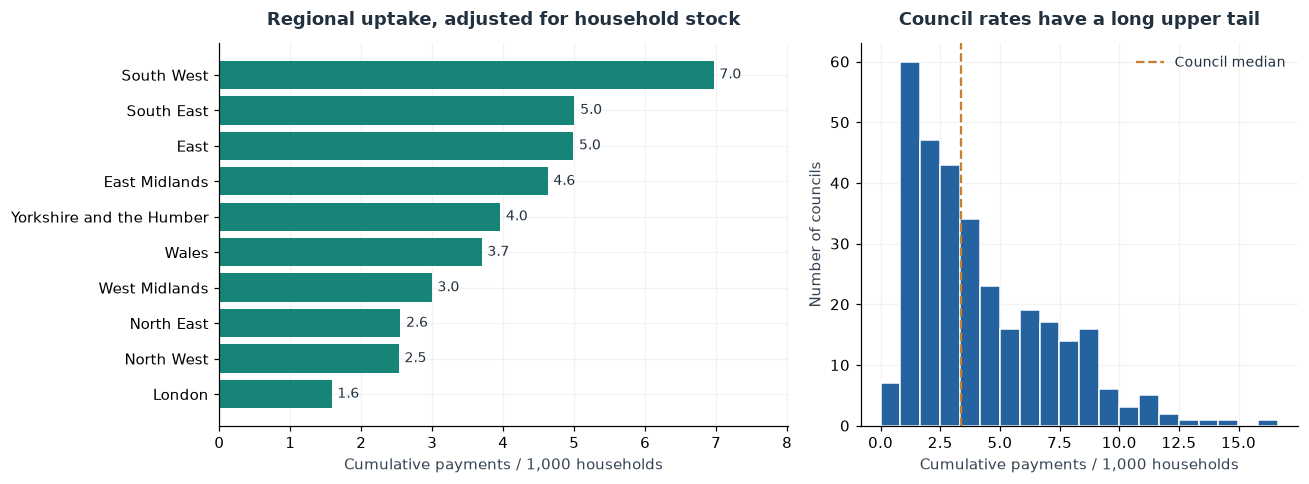

Regional rates range from 1.58 to 6.97 per 1,000 households. The council median is 3.38; a small number of areas have much higher uptake.

In [28]:
regional_rates = councils.groupby("region").agg(
    councils=("code", "size"), paid=("paid", "sum"), households=("households", "sum")
)
regional_rates["paid_per_1000"] = 1000 * regional_rates.paid / regional_rates.households
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
ordered = regional_rates.sort_values("paid_per_1000")
axes[0].barh(ordered.index, ordered.paid_per_1000, color=TEAL)
axes[0].set(
    title="Regional uptake, adjusted for household stock",
    xlabel="Cumulative payments / 1,000 households",
)
for i, value in enumerate(ordered.paid_per_1000):
    axes[0].text(value + 0.08, i, f"{value:.1f}", va="center", fontsize=9)
axes[0].set_xlim(0, ordered.paid_per_1000.max() * 1.15)
axes[1].hist(councils.rate_per_1000, bins=20, color=BLUE, edgecolor="white")
axes[1].axvline(councils.rate_per_1000.median(), color=ORANGE, ls="--", label="Council median")
axes[1].set(
    title="Council rates have a long upper tail",
    xlabel="Cumulative payments / 1,000 households",
    ylabel="Number of councils",
)
axes[1].legend(frameon=False, fontsize=9)
save_plot("regional_rates")
regional_rates.to_csv(OUT / "regional_uptake_rates.csv")
display(
    Markdown(
        f"Regional rates range from {ordered.paid_per_1000.min():.2f} to {ordered.paid_per_1000.max():.2f} per 1,000 households. The council median is {councils.rate_per_1000.median():.2f}; a small number of areas have much higher uptake."
    )
)

### Which housing characteristics are associated with uptake?

Detached housing, tenure and gas access overlap. These plots show unadjusted council-level associations; they do not describe individual household behaviour. The models below consider six characteristics jointly, including oil-only and electric-only central heating.

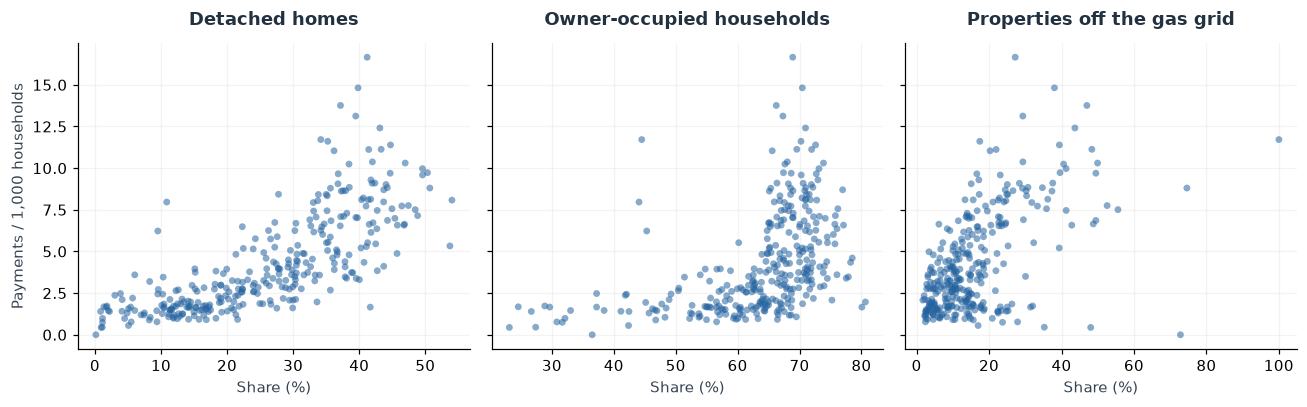

Detached share correlates with uptake at 0.75. Oil-only heating and off-gas shares also overlap (r=0.75), so individual model coefficients need care.

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, feature, label in zip(
    axes,
    ["detached_share", "owner_share", "offgas_share"],
    ["Detached homes", "Owner-occupied households", "Properties off the gas grid"],
):
    ax.scatter(
        100 * councils[feature],
        councils.rate_per_1000,
        s=20,
        color=BLUE,
        alpha=0.55,
        edgecolors="none",
    )
    ax.set(title=label, xlabel="Share (%)")
axes[0].set_ylabel("Payments / 1,000 households")
save_plot("council_associations")
councils[features + ["rate_per_1000"]].corr().to_csv(OUT / "council_correlations.csv")
display(
    Markdown(
        f"Detached share correlates with uptake at {councils.detached_share.corr(councils.rate_per_1000):.2f}. Oil-only heating and off-gas shares also overlap (r={councils.oil_share.corr(councils.offgas_share):.2f}), so individual model coefficients need care."
    )
)

## 7. Predict uptake on held-out regions

We compare a pooled-rate baseline, Poisson, negative binomial and shallow gradient boosting. Count models use a household offset; boosting fits household-weighted rates. Five frozen geographic folds keep whole regions out of training. No outcome-derived features or tuning are used; lower validation error is better.

In [30]:
X = sm.add_constant(councils[features] * 10, has_constant="add").astype(float)
y = councils.paid.to_numpy(dtype=float)
exposure = councils.households.to_numpy(dtype=float)
offset = np.log(exposure)
poisson_full = sm.GLM(y, X, family=sm.families.Poisson(), offset=offset).fit(cov_type="HC0")
dispersion = float(np.sum(poisson_full.resid_pearson**2) / poisson_full.df_resid)
# Keep the original geographic split explicit and independent of library tie-breaking.
region_folds = {
    "South East": 1,
    "East": 2,
    "Yorkshire and the Humber": 2,
    "North West": 3,
    "South West": 3,
    "East Midlands": 4,
    "North East": 4,
    "Wales": 4,
    "London": 5,
    "West Midlands": 5,
}
folds_path = PROCESSED / "geographic_cv_folds.csv"
current_folds = councils[["code", "region"]].assign(
    fold=councils.region.map(region_folds), model_row=councils.index
)
assert current_folds.fold.notna().all()
if folds_path.exists():
    saved_folds = pd.read_csv(folds_path)
    pd.testing.assert_frame_equal(current_folds, saved_folds, check_dtype=False)
else:
    current_folds.to_csv(folds_path, index=False)
fold_ids = current_folds.fold.to_numpy()
splits = [
    (np.flatnonzero(fold_ids != fold), np.flatnonzero(fold_ids == fold)) for fold in range(1, 6)
]
groups = councils.region
display(
    current_folds.groupby("fold").agg(
        councils=("code", "size"),
        held_out_regions=("region", lambda values: ", ".join(sorted(set(values)))),
    )
)
display(
    Markdown(
        f"Poisson's conditional Pearson dispersion is {dispersion:.1f}, well above one. Negative binomial allows this extra variation; all models use the same held-out councils."
    )
)

,councils,held_out_regions
fold,,
1,64,South East
2,58,"East, Yorkshire and the Humber"
3,62,"North West, South West"
4,69,"East Midlands, North East, Wales"
5,63,"London, West Midlands"


Poisson's conditional Pearson dispersion is 41.9, well above one. Negative binomial allows this extra variation; all models use the same held-out councils.

In [31]:
model_names = ["Pooled rate", "Poisson", "Negative binomial", "Gradient boosting"]
oof = pd.DataFrame(index=councils.index, columns=model_names, dtype=float)
fold_rows, convergence_rows = ([], [])
with threadpool_limits(limits=1):
    for fold, (train_idx, test_idx) in enumerate(splits, 1):
        assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
        xtr, xte = (X.iloc[train_idx], X.iloc[test_idx])
        ytr = y[train_idx]
        poisson = sm.GLM(ytr, xtr, family=sm.families.Poisson(), offset=offset[train_idx]).fit()
        nb = sm.NegativeBinomial(ytr, xtr, offset=offset[train_idx], loglike_method="nb2").fit(
            disp=False, maxiter=300
        )
        converged = bool(nb.mle_retvals["converged"])
        assert converged, f"NB fold {fold} failed to converge"
        tree = HistGradientBoostingRegressor(
            loss="poisson",
            learning_rate=0.05,
            max_iter=120,
            max_leaf_nodes=5,
            min_samples_leaf=20,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=SEED,
        )
        tree.fit(
            councils.loc[train_idx, features],
            1000 * ytr / exposure[train_idx],
            sample_weight=exposure[train_idx],
        )
        pred = {
            "Pooled rate": exposure[test_idx] * ytr.sum() / exposure[train_idx].sum(),
            "Poisson": poisson.predict(xte, offset=offset[test_idx]),
            "Negative binomial": nb.predict(xte, offset=offset[test_idx]),
            "Gradient boosting": tree.predict(councils.loc[test_idx, features])
            * exposure[test_idx]
            / 1000,
        }
        for name, values in pred.items():
            values = np.asarray(values)
            assert np.isfinite(values).all() and (values > 0).all()
            oof.loc[test_idx, name] = values
            fold_rows.append(
                {
                    "fold": fold,
                    "held_out_regions": ", ".join(sorted(set(groups.iloc[test_idx]))),
                    "model": name,
                    "n": len(test_idx),
                    "MAE_count": mean_absolute_error(y[test_idx], values),
                    "MAE_per_1000": mean_absolute_error(
                        1000 * y[test_idx] / exposure[test_idx], 1000 * values / exposure[test_idx]
                    ),
                    "Poisson_deviance": mean_poisson_deviance(y[test_idx], values),
                }
            )
        convergence_rows.append(
            {"fold": fold, "NB_converged": converged, "alpha": float(nb.params.iloc[-1])}
        )

In [32]:
assert oof.notna().all().all()
metrics = pd.DataFrame(
    [
        {
            "model": name,
            "MAE_count": mean_absolute_error(y, oof[name]),
            "MAE_per_1000": mean_absolute_error(1000 * y / exposure, 1000 * oof[name] / exposure),
            "Poisson_deviance": mean_poisson_deviance(y, oof[name]),
        }
        for name in model_names
    ]
).set_index("model")
fold_metrics = pd.DataFrame(fold_rows)
metrics.to_csv(OUT / "geographic_cv_metrics.csv")
fold_metrics.to_csv(OUT / "geographic_cv_fold_metrics.csv", index=False)
pd.concat([councils[["code", "name", "region"]], oof], axis=1).to_csv(
    OUT / "council_out_of_fold_predictions.csv", index=False
)
winner = metrics.MAE_per_1000.idxmin()
pd.DataFrame(convergence_rows).to_csv(OUT / "count_model_convergence.csv", index=False)
display(metrics.round(3))

,MAE_count,MAE_per_1000,Poisson_deviance
model,,,
Pooled rate,184.061,2.412,159.024
Poisson,102.142,1.536,54.938
Negative binomial,113.191,1.696,65.737
Gradient boosting,83.419,1.214,38.972


### Which model predicts most accurately?

Rate MAE treats councils equally; count MAE and Poisson deviance give more weight to large count errors. Dots show fold-specific performance, not confidence intervals. Comparing candidates and reporting their winning CV score introduces selection optimism; there is no independent final test set.

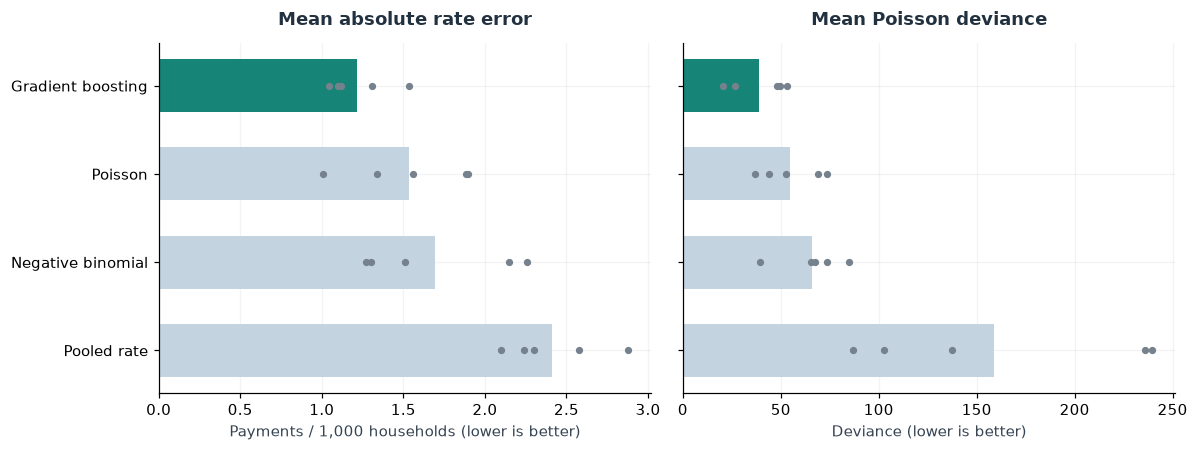

**Gradient boosting** has the lowest rate MAE: 1.214, versus 2.412 for the pooled baseline. Performance still varies across held-out regions.

In [33]:
ordered_metrics = metrics.sort_values("MAE_per_1000", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, metric, title in zip(
    axes,
    ["MAE_per_1000", "Poisson_deviance"],
    ["Mean absolute rate error", "Mean Poisson deviance"],
):
    positions = np.arange(len(ordered_metrics))
    colours = [TEAL if name == winner else "#C4D3E0" for name in ordered_metrics.index]
    ax.barh(positions, ordered_metrics[metric], color=colours, height=0.6)
    for i, name in enumerate(ordered_metrics.index):
        values = fold_metrics.loc[fold_metrics.model.eq(name), metric]
        ax.scatter(values, np.full(len(values), i), s=14, color=GREY, zorder=3)
    ax.set_yticks(positions, ordered_metrics.index)
    ax.set_title(title)
axes[0].set_xlabel("Payments / 1,000 households (lower is better)")
axes[1].set_xlabel("Deviance (lower is better)")
save_plot("model_performance")
display(
    Markdown(
        f"**{winner}** has the lowest rate MAE: {metrics.loc[winner,'MAE_per_1000']:.3f}, versus {metrics.loc['Pooled rate','MAE_per_1000']:.3f} for the pooled baseline. Performance still varies across held-out regions."
    )
)

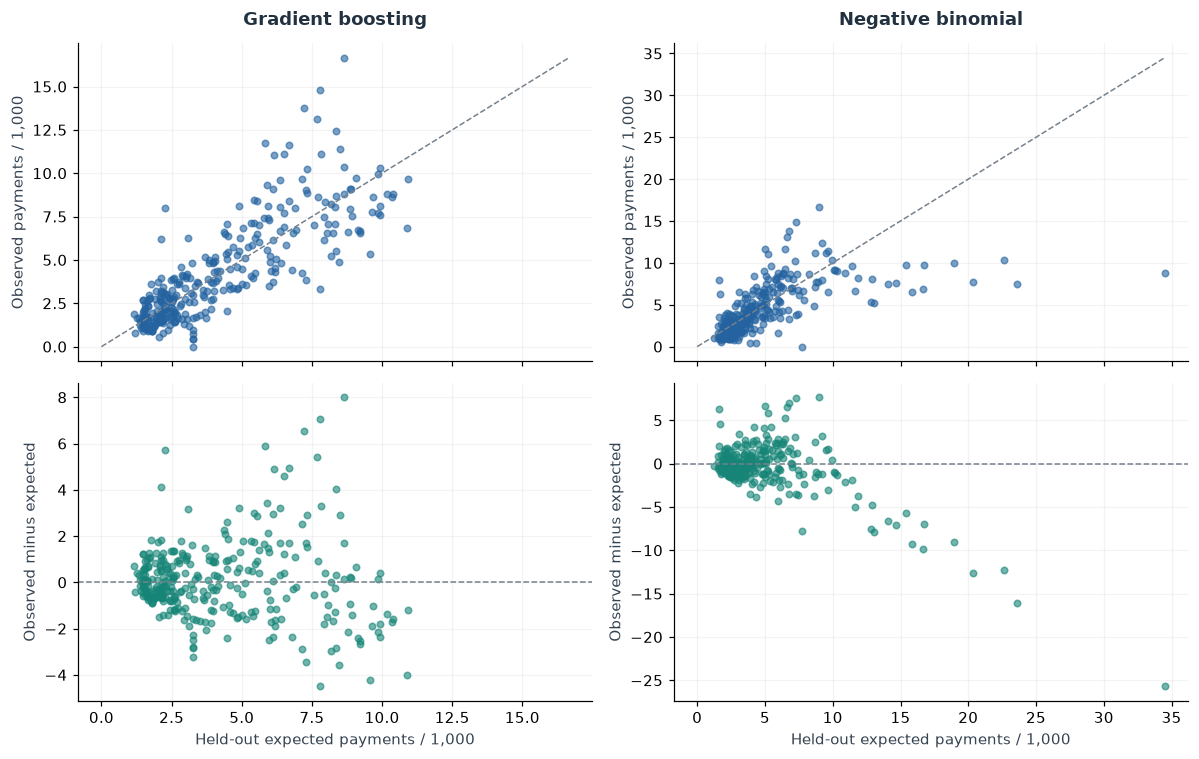

The tree model follows observed rates more closely. Negative binomial overpredicts some high-rate expectations, which makes its most extreme council gaps particularly model-sensitive.

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex="col")
for column, name in enumerate(["Gradient boosting", "Negative binomial"]):
    predicted_rate = 1000 * oof[name] / exposure
    actual_rate = councils.rate_per_1000
    upper = max(predicted_rate.max(), actual_rate.max())
    axes[0, column].scatter(predicted_rate, actual_rate, s=18, alpha=0.6, color=BLUE)
    axes[0, column].plot([0, upper], [0, upper], ls="--", color=GREY, lw=1)
    axes[0, column].set(title=name, ylabel="Observed payments / 1,000")
    axes[1, column].scatter(
        predicted_rate, actual_rate - predicted_rate, s=18, alpha=0.6, color=TEAL
    )
    axes[1, column].axhline(0, color=GREY, ls="--", lw=1)
    axes[1, column].set(
        xlabel="Held-out expected payments / 1,000", ylabel="Observed minus expected"
    )
save_plot("expected_observed")
display(
    Markdown(
        "The tree model follows observed rates more closely. Negative binomial overpredicts some high-rate expectations, which makes its most extreme council gaps particularly model-sensitive."
    )
)

## 8. Explain associations and uptake gaps

Negative-binomial coefficients summarise adjusted associations, even though boosting predicts better. Ratios below describe a **10 percentage-point increase**, holding other features fixed. The intervals assume independent councils and are exploratory; regional adjustment shows sensitivity to broad geographic differences.

In [35]:
nb_full = sm.NegativeBinomial(y, X, offset=offset, loglike_method="nb2").fit(
    disp=False, maxiter=300, cov_type="HC0"
)
assert nb_full.mle_retvals["converged"]
alpha_full = float(nb_full.params.iloc[-1])
ci = nb_full.conf_int().loc[features]
coefficients = pd.DataFrame(
    {
        "rate_ratio_10pp": np.exp(nb_full.params.loc[features]),
        "CI_low": np.exp(ci[0]),
        "CI_high": np.exp(ci[1]),
        "p_value_exploratory": nb_full.pvalues.loc[features],
    }
)
region_dummies = pd.get_dummies(councils.region, prefix="region", drop_first=True, dtype=float)
region_X = pd.concat([X, region_dummies], axis=1)
region_model = sm.GLM(
    y, region_X, family=sm.families.NegativeBinomial(alpha=alpha_full), offset=offset
).fit(cov_type="HC0")
coefficients["region_adjusted_ratio_10pp"] = np.exp(region_model.params.loc[features])
coefficients.to_csv(OUT / "negative_binomial_associations.csv")
display(
    coefficients[["rate_ratio_10pp", "CI_low", "CI_high", "region_adjusted_ratio_10pp"]].round(2)
)

,rate_ratio_10pp,CI_low,CI_high,region_adjusted_ratio_10pp
detached_share,1.41,1.30,1.53,1.33
flat_share,1.03,0.96,1.10,1.02
owner_share,1.09,0.97,1.24,1.03
oil_share,1.04,0.75,1.44,0.90
electric_share,0.96,0.69,1.33,0.53
offgas_share,1.18,0.98,1.42,1.37


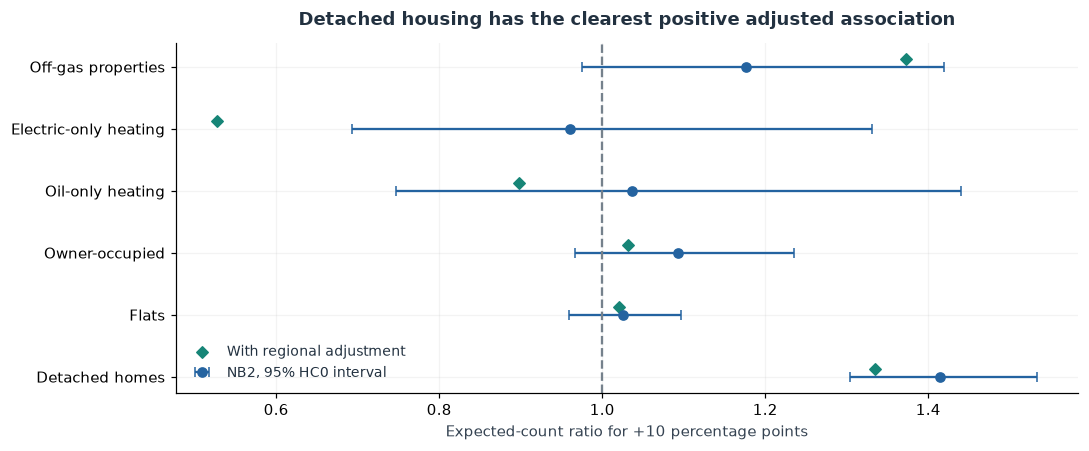

A 10-point higher detached share is associated with a 1.41× expected count, or 1.33× with regional adjustment. Other associations are less precise or more sensitive to adjustment.

In [36]:
feature_labels = [
    "Detached homes",
    "Flats",
    "Owner-occupied",
    "Oil-only heating",
    "Electric-only heating",
    "Off-gas properties",
]
fig, ax = plt.subplots(figsize=(10, 4.2))
positions = np.arange(len(features))
ax.errorbar(
    coefficients.rate_ratio_10pp,
    positions,
    xerr=np.vstack(
        [
            coefficients.rate_ratio_10pp - coefficients.CI_low,
            coefficients.CI_high - coefficients.rate_ratio_10pp,
        ]
    ),
    fmt="o",
    color=BLUE,
    capsize=3,
    label="NB2, 95% HC0 interval",
)
ax.scatter(
    coefficients.region_adjusted_ratio_10pp,
    positions + 0.12,
    color=TEAL,
    marker="D",
    s=28,
    label="With regional adjustment",
)
ax.axvline(1, color=GREY, ls="--")
ax.set_yticks(positions, feature_labels)
ax.set(
    xlabel="Expected-count ratio for +10 percentage points",
    title="Detached housing has the clearest positive adjusted association",
)
ax.legend(frameon=False, fontsize=9, loc="lower left")
save_plot("nb_associations")
display(
    Markdown(
        f"A 10-point higher detached share is associated with a {coefficients.loc['detached_share','rate_ratio_10pp']:.2f}× expected count, or {coefficients.loc['detached_share','region_adjusted_ratio_10pp']:.2f}× with regional adjustment. Other associations are less precise or more sensitive to adjustment."
    )
)

In [37]:
gaps = councils[["code", "name", "region", "paid", "households", "rate_per_1000"]].copy()
gaps["expected_NB_oof"] = oof["Negative binomial"]
gaps["expected_rate_NB_oof"] = 1000 * gaps.expected_NB_oof / gaps.households
gaps["gap_per_1000"] = gaps.rate_per_1000 - gaps.expected_rate_NB_oof
gaps["observed_to_expected"] = gaps.paid / gaps.expected_NB_oof
gaps["expected_CV_winner_oof"] = oof[winner]
gaps["expected_rate_CV_winner_oof"] = 1000 * oof[winner] / gaps.households
gaps["gap_CV_winner_per_1000"] = gaps.rate_per_1000 - gaps.expected_rate_CV_winner_oof
candidate_rates = (
    oof[["Poisson", "Negative binomial", "Gradient boosting"]].div(councils.households, axis=0)
    * 1000
)
gaps["candidate_expected_rate_min"] = candidate_rates.min(axis=1)
gaps["candidate_expected_rate_max"] = candidate_rates.max(axis=1)
gaps["below_all_candidate_predictions"] = councils.rate_per_1000 < candidate_rates.min(axis=1)
gaps = gaps.sort_values("gap_per_1000")
gaps.to_csv(OUT / "descriptive_uptake_gaps.csv", index=False)
gap_table = gaps.sort_values("gap_CV_winner_per_1000")
display(
    gap_table[
        [
            "name",
            "region",
            "rate_per_1000",
            "expected_rate_CV_winner_oof",
            "gap_CV_winner_per_1000",
            "below_all_candidate_predictions",
        ]
    ]
    .head(10)
    .round(2)
)

,name,region,rate_per_1000,expected_rate_CV_winner_oof,gap_CV_winner_per_1000,below_all_candidate_predictions
146,Tendring,East,3.31,7.80,-4.49,True
85,South Holland,East Midlands,5.33,9.57,-4.24,True
161,King’s Lynn and West Norfolk,East,6.86,10.87,-4.01,True
133,Fenland,East,4.88,8.45,-3.57,True
81,Boston,East Midlands,3.84,7.28,-3.44,True
171,City of London,London,0.00,3.25,-3.25,True
303,Carmarthenshire / Sir Gaerfyrddin,Wales,5.21,8.17,-2.96,True
137,Braintree,East,4.26,7.14,-2.87,True
181,Tower Hamlets,London,0.44,3.27,-2.83,True
169,West Suffolk,East,5.52,8.35,-2.82,True


### Where is uptake below model expectations?

We prioritise the best-performing model's held-out rate gaps and compare the other candidates. The range below is model disagreement, not a confidence interval. A negative gap is a prompt for local investigation, not evidence of policy failure or individual disadvantage.

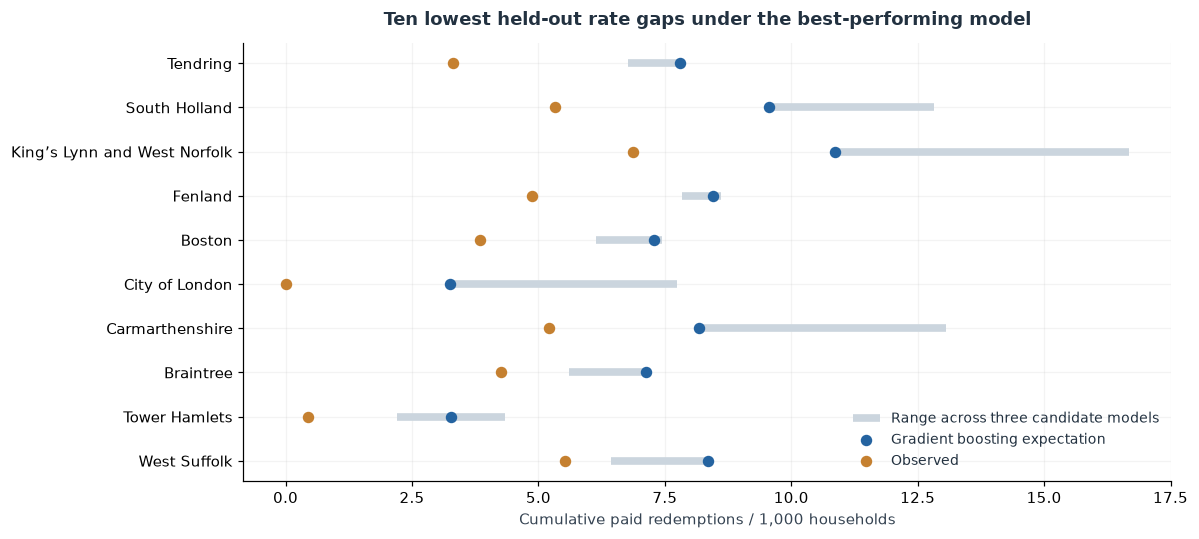

Tendring has the largest negative gradient boosting rate gap (-4.49/1,000). Ceredigion's expected rate varies from 10.2 to 34.5 across models, illustrating why rankings need caution.

In [38]:
shortlist = gap_table.head(10).iloc[::-1]
positions = np.arange(len(shortlist))
fig, ax = plt.subplots(figsize=(11, 5))
ax.hlines(
    positions,
    shortlist.candidate_expected_rate_min,
    shortlist.candidate_expected_rate_max,
    color="#CBD5DE",
    lw=5,
    label="Range across three candidate models",
)
ax.scatter(
    shortlist.expected_rate_CV_winner_oof,
    positions,
    color=BLUE,
    s=42,
    label=winner + " expectation",
    zorder=3,
)
ax.scatter(shortlist.rate_per_1000, positions, color=ORANGE, s=42, label="Observed", zorder=3)
ax.set_yticks(positions, shortlist.name.str.split(" / ").str[0])
ax.set(
    xlabel="Cumulative paid redemptions / 1,000 households",
    title="Ten lowest held-out rate gaps under the best-performing model",
)
ax.legend(frameon=False, fontsize=9, loc="lower right")
save_plot("uptake_gaps")
lowest = gap_table.iloc[0]
ceredigion = gaps.loc[gaps.code.eq("W06000008")].iloc[0]
display(
    Markdown(
        f"{lowest['name']} has the largest negative {winner.lower()} rate gap ({lowest.gap_CV_winner_per_1000:.2f}/1,000). Ceredigion's expected rate varies from {ceredigion.candidate_expected_rate_min:.1f} to {ceredigion.candidate_expected_rate_max:.1f} across models, illustrating why rankings need caution."
    )
)

## 9. What can we conclude?

There is a clear change in recorded applications around the uplift, but this design cannot establish how much the grant caused. Council models identify descriptive differences worth investigating; they cannot measure unmet demand or fairness without eligibility, affordability and delivery data.

In [39]:
app = contrasts.set_index("outcome").loc["applications"]
paid_contrast = contrasts.set_index("outcome").loc["paid"]
best_metrics = metrics.loc[winner]
display(
    pd.DataFrame(
        [
            {
                "Question": "National activity",
                "Finding": f"Applications +{before_after.loc['applications','change_pct']:.1f}%; payments +{before_after.loc['paid','change_pct']:.1f}% in selected windows",
            },
            {
                "Question": "Trend-adjusted contrast",
                "Finding": f"Applications {app.average_post_contrast:+,.0f}/month; payments {paid_contrast.average_post_contrast:+,.0f}/month",
            },
            {
                "Question": "Council prediction",
                "Finding": f"{winner}: rate MAE {best_metrics.MAE_per_1000:.3f}/1,000 households",
            },
            {
                "Question": "Interpretation",
                "Finding": "Observed associations and descriptive gaps; no identified causal effect",
            },
        ]
    )
)
summary = {
    "monthly_observations": len(national),
    "councils_modelled": len(councils),
    "cumulative_paid_hydronic": float(national.paid.sum()),
    "applications_before_after_pct": float(before_after.loc["applications", "change_pct"]),
    "paid_before_after_pct": float(before_after.loc["paid", "change_pct"]),
    "geographic_cv_rate_MAE_winner": winner,
    "geographic_cv_metrics": metrics.reset_index().to_dict(orient="records"),
    "its_contrasts": contrasts.to_dict(orient="records"),
    "poisson_dispersion": dispersion,
    "NB_alpha": alpha_full,
    "lowest_NB_rate_gaps": gaps.head(5).to_dict(orient="records"),
    "lowest_winner_rate_gaps": gap_table.head(5).to_dict(orient="records"),
}
summary_path = OUT / "analysis_summary.json"
_ = summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

,Question,Finding
0,National activity,Applications +48.0%; payments +52.8% in selected windows
1,Trend-adjusted contrast,Applications +908/month; payments -31/month
2,Council prediction,"Gradient boosting: rate MAE 1.214/1,000 households"
3,Interpretation,Observed associations and descriptive gaps; no identified causal effect


**Limits:** short pre/post windows, anticipation, payment lags, revised data and later policy changes weaken attribution. Census households are an old exposure proxy; two councils are excluded, and geographic prediction remains uncertain.

No credible untreated control supports difference-in-differences. Arbitrary classification and clustering add little; monthly council histories and deprivation data are absent. ICF's published **74% scheme additionality** concerns the whole scheme, not this grant uplift.

See the [policy summary](../policy_summary.md) for the nontechnical findings and [README](../README.md) for sources and methods.

### Technical Concepts I Need to Understand Before My ICF Interview

- Why are applications, payments and commissioning different outcomes?
- How do suppression, hierarchy totals and boundary changes affect a join?
- What does a household offset assume?
- What do HAC intervals address, and what confounding remains?
- Why use NB2 when conditional Poisson variance is too small?
- How do frozen geographic folds prevent leakage?
- Why can good prediction coexist with weak causal identification?
- Why is a council gap neither household behaviour nor policy failure?

In [40]:
assert raw_hashes() == initial_hashes == json.loads(manifest_path.read_text())
assert np.isclose(la.paid.sum(), national.paid.sum())
assert councils.code.is_unique and councils[required].notna().all().all()
assert np.isfinite(oof.to_numpy()).all() and (oof > 0).all().all()
assert np.isfinite(metrics.to_numpy()).all()
assert set(councils.code).issubset(set(la.code))
assert len(current_folds) == len(councils) and current_folds.code.is_unique
for train_idx, test_idx in splits:
    assert set(councils.region.iloc[train_idx]).isdisjoint(councils.region.iloc[test_idx])
display(
    pd.DataFrame(
        {
            "Check": [
                "Six raw-file hashes",
                "National/district reconciliation",
                "Model inputs and predictions",
                "Geographic fold separation",
            ],
            "Result": ["Passed"] * 4,
        }
    )
)

,Check,Result
0,Six raw-file hashes,Passed
1,National/district reconciliation,Passed
2,Model inputs and predictions,Passed
3,Geographic fold separation,Passed
